# Calibration With Three Receivers

## Intro

It has long been known that full error correction is possible given a VNA with only three receivers and no internal coaxial switch. However, since no modern VNA employs such an architecture, the software required to make fully corrected measurements is not available on today's modern VNA's. 

Recently, the application of Frequency Extender units containing only three receivers has become more common. Furthermore, low-cost VNAs are becoming useful tools for learning RF electronics. The representative example is NanoVNA, which uses a three-receiver design. Thus, there is a need for full error correction capability on systems with three receivers and no  internal coaxial switch. This document describes how to use [scikit-rf](http://www.scikit-rf.org) to fully correct two-port measurements made on such a system.

## Theory

A circuit model for a switch-less three receiver system is shown below.

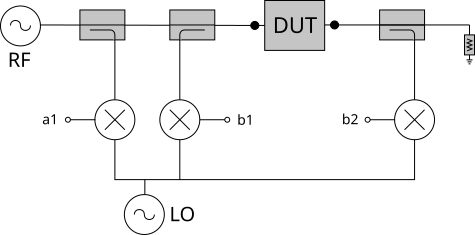

In [1]:
from IPython.display import SVG, Image

SVG('three_receiver_cal/pics/vnaBlockDiagramForwardRotated.svg')

To fully correct an arbitrary two-port,  the device must be measured in two orientations, call these forward and reverse. Because there is no switch present, this requires the operator to physically flip the device, and save the pair of measurements. In on-wafer scenarios, one could fabricate two identical devices, one in each orientation. In either case, a pair of  measurements are required for each DUT before correction can occur. 

While in reality the device is being flipped, one can imaging that the device is static, and the entire VNA circuitry is flipped. This interpretation lends itself to implementation, as the existing 12-term correction can be reused by simply copying the forward error coefficients into the corresponding reverse error coefficients. This is what `scikit-rf` does internally.



## Worked Example

This example demonstrates how to create a [TwoPortOnePath](../../api/calibration/generated/skrf.calibration.calibration.TwoPortOnePath.rst) and [EnhancedResponse](../../api/calibration/generated/skrf.calibration.calibration.EnhancedResponse.rst) calibration from  measurements taken on a Agilent PNAX with a set of VDI WR-12 TXRX-RX Frequency Extender heads.  Comparisons between the two algorithms are made by correcting an asymmetric  DUT.

### Measure the Calibration Standands and DUT

First, one measures the S-parameters of the Open, Short, and Load standards on the VNA according to the standard SOLT calibration procedures. We assume the reader is familiar with this task in scikit-rf. If not, it's fully described in the [SOLT example](./SOLT.ipynb).

When calibrating a three-receiver VNA, the process is almost identical. But note that there are a few minor differences. First, the Open, Short, and Load standards are only measured at port 1, not port 2. The VNA cannot measure in the reverse orientation, so there's no reason to perform OSL calibration at port 2 (unless one needs the optional isolation calibration). 

Nevetheless, scikit-rf still expects two-port networks as input, we therefore still save all results as two-port networks. In this case, only $S_{11}$ and $S_{21}$ are the actual measurements, $S_{12}$ and $S_{22}$ are unused, not meaningful, and can contain arbitrary data. One can use all-zero values as placeholders. Internally, scikit-rf will set $S_{22} = S_{11}$ and $S_{12} = S_{21}$ for the purpose of calculations.

Then, the DUT is measured as a two-port network in the forward direction, physically flipped, and then measured again in the reverse orientation.

### Read in the Data

The measurements of the calibration standards and DUT's  were downloaded from the VNA by saving touchstone files of the raw s-parameter data to disk. 

In [2]:
! ls three_receiver_cal/data/

'attenuator (forward).s2p'	 simulation.s2p
'attenuator (reverse).s2p'	 thru.s2p
 load.s2p			'wr15 shim and swg (forward).s2p'
'quarter wave delay short.s2p'	'wr15 shim and swg (reverse).s2p'
 short.s2p


These files can be read by scikit-rf into `Network`s with the following. 

In [3]:
import matplotlib.pyplot as plt

import skrf as rf

%matplotlib inline

rf.stylely()


raw = rf.io.general.read_all_networks('three_receiver_cal/data/')
# list the raw measurements
raw.keys()

dict_keys(['attenuator (forward)', 'attenuator (reverse)', 'load', 'quarter wave delay short', 'short', 'simulation', 'thru', 'wr15 shim and swg (forward)', 'wr15 shim and swg (reverse)'])

Each `Network` can be accessed through the dictionary `raw`.

In [4]:
thru = raw['thru']
thru

2-Port Network: 'thru',  60.0-90.0 GHz, 721 pts, z0=[50.+0.j 50.+0.j]

If we look at the *raw* measurement of the flush thru, it can be seen that only $S_{11}$ and $S_{21}$ contain meaningful data.  The other s-parameters are noise. 

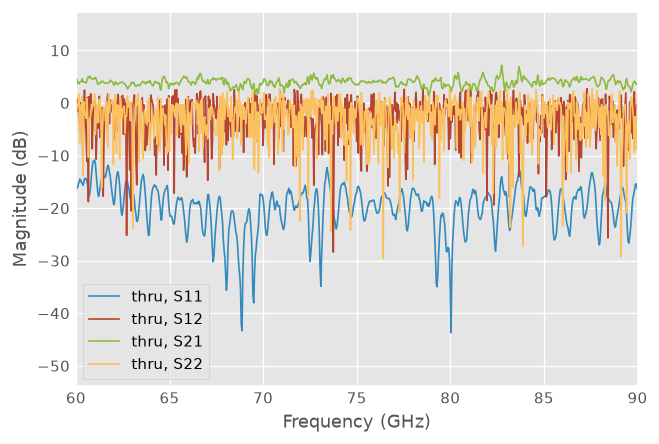

In [5]:
thru.plot_s_db()

### Create Calibration 

In the code that follows a TwoPortOnePath calibration is created from corresponding  measured and ideal responses of the calibration standards. The measured networks are read from disk, while their corresponding ideal responses are generated using scikit-rf. More information about using scikit-rf to do offline calibrations can be found [here](../../tutorials/Calibration.ipynb).

In [6]:

from skrf.calibration import TwoPortOnePath
from skrf.constants import mil
from skrf.media import RectangularWaveguide
from skrf.network import two_port_reflect as tpr

# pull frequency information from measurements
frequency = raw['short'].frequency

# the media object
wg = RectangularWaveguide(frequency=frequency, a=120*mil, z0_override=50)

# list of 'ideal' responses of the calibration standards
ideals = [wg.short(nports=2),
          tpr(wg.delay_short( 90,'deg'), wg.match()),
          wg.match(nports=2),
          wg.thru()]

# corresponding measurements to the 'ideals'
measured = [raw['short'],
            raw['quarter wave delay short'],
            raw['load'],
            raw['thru']]

# the Calibration object
cal = TwoPortOnePath(measured = measured, ideals = ideals)

/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:2073: UserWarning: n_thrus is None, guessing which stds are transmissive
  TwelveTerm.__init__(self,*args, **kwargs)


By default, `TwoPortOnePath` assumes port 1 is the active source in all calibrations and measurements (thus only $S_{11}$ and $S_{21}$ are valid data). If, for some reason, the valid measurements are presented as $S_{12}$ and $S_{22}$, one can set the optional parameter `source_port=2` when creating the `TwoPortOnePath` object.


### Apply Correction

There are two types of correction possible with a 3-receiver system. 

1. Full (TwoPortOnePath)
2. Partial  (EnhancedResponse)

`scikit-rf` uses the same `Calibration` object for both, but employs different correction  algorithms depending on  the `type` of the DUT. The DUT used in  this example is a WR-15 shim  cascaded with a WR-12 1" straight waveguide, as shown in the picture below.  Measurements of this DUT are corrected with both *full* and *partial* correction and the results are compared below. 

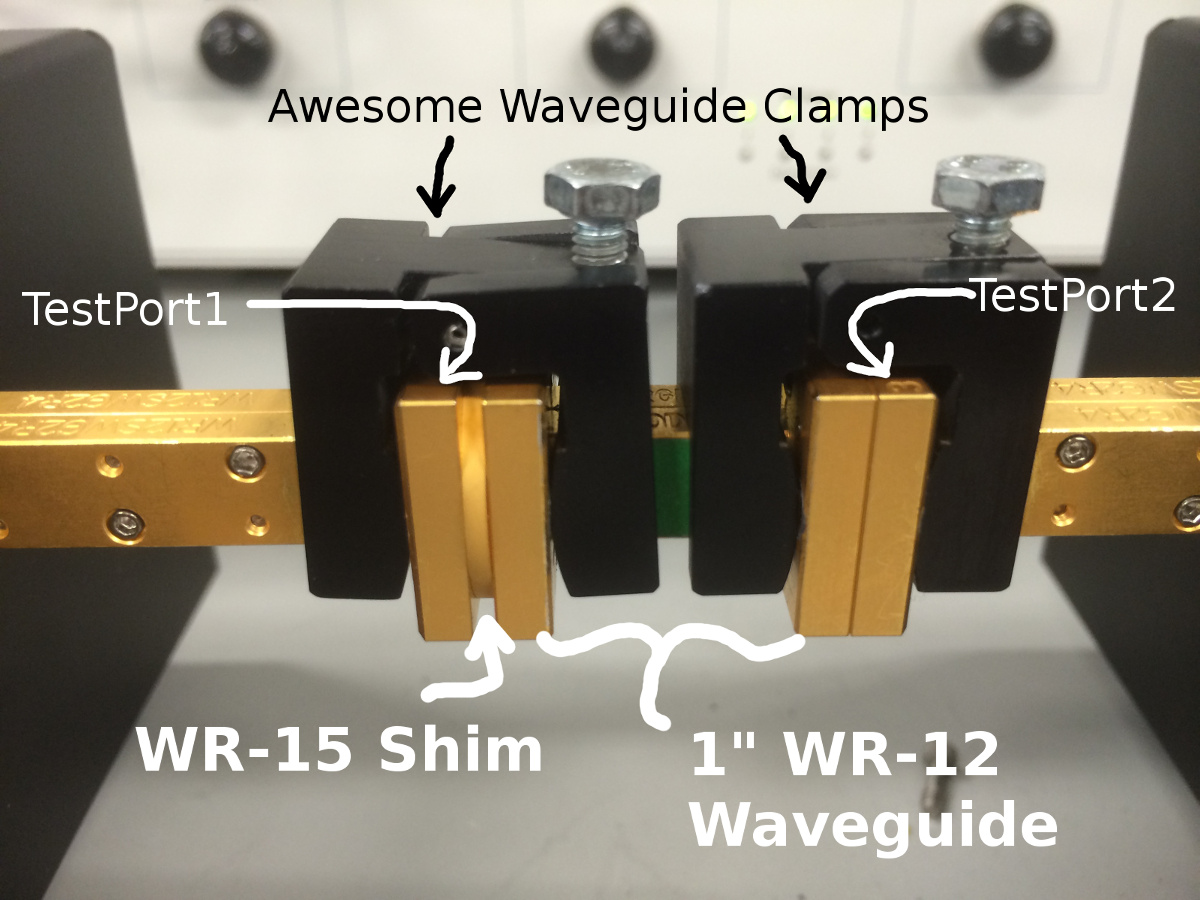

In [7]:
Image('three_receiver_cal/pics/asymmetic DUT.jpg', width='75%')

#### Full Correction ( TwoPortOnePath)

Full correction is achieved by measuring each device in both orientations, **forward** and **reverse**. To be clear, this means that  the DUT must be  physically removed, flipped, and re-inserted. The resulting pair of  measurements are then passed to the `apply_cal()` function as a tuple. This returns a single corrected response.  



#### Partial Correction (Enhanced Response)

If you pass a single measurement to the `apply_cal()` function, then the calibration will employ partial correction. This type of correction is known as `EnhancedResponse`. Depending on the measurement application, this type of correction may be  *good enough*, and perhaps the only choice.

### Comparison

Below are direct comparisons of the DUT shown above corrected with *full* and *partial* algorithms. It shows that the partial calibration produces a large ripple on the reflect measurements, and slightly larger ripple on the transmissive measurements. 

/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:575: UserWarning: The system is singular at 60.0 GHz. Ensure that the standards are far enough away from each other on the Smith chart.
  self.run()
/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:575: UserWarning: The system is singular at 60.0416666667 GHz. Ensure that the standards are far enough away from each other on the Smith chart.
  self.run()
/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:575: UserWarning: The system is singular at 60.0833333333 GHz. Ensure that the standards are far enough away from each other on the Smith chart.
  self.run()
/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:575: UserWarning: The system is singular at 60.125 GHz. Ensure that the standards are far enough away from each other on the Smith chart.
  self.run()
/home/alex/code/scikit-rf-docs/skrf/calibration/calibration.py:575: UserWarning: The system is singular at 60.1666666667 GHz. Ensure

/tmp/ipykernel_777254/1667802585.py:7: UserWarning: only gave a single measurement orientation, error correction is partial without a tuple
  corrected_partial =  cal.apply_cal(dutf)
/home/alex/code/scikit-rf-docs/skrf/mathFunctions.py:303: RuntimeWarning: divide by zero encountered in log10
  out = 20 * np.log10(z)


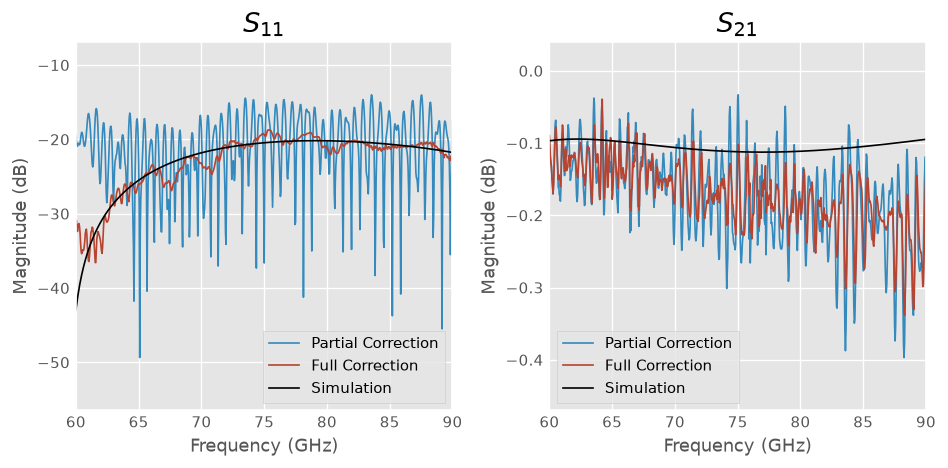

In [8]:
simulation = raw['simulation']

dutf = raw['wr15 shim and swg (forward)']
dutr = raw['wr15 shim and swg (reverse)']

corrected_full =     cal.apply_cal((dutf, dutr))
corrected_partial =  cal.apply_cal(dutf)



# plot results

f, ax = plt.subplots(1,2, figsize=(8,4))

ax[0].set_title ('$S_{11}$')
ax[1].set_title ('$S_{21}$')

corrected_partial.plot_s_db(0,0, label='Partial Correction',ax=ax[0])
corrected_partial.plot_s_db(1,0, label='Partial Correction',ax=ax[1])

corrected_full.plot_s_db(0,0, label='Full Correction', ax = ax[0])
corrected_full.plot_s_db(1,0, label='Full Correction', ax = ax[1])

simulation.plot_s_db(0,0,label='Simulation', ax=ax[0], color='k')
simulation.plot_s_db(1,0,label='Simulation', ax=ax[1], color='k')

plt.tight_layout()

### What if my DUT is Symmetric??

If the DUT is known to be **reciprocal** ( $S_{21}=S_{12}$ ) and **symmetric** ( $S_{11}=S_{22}$ ), then its response should be the identical for both forward and reverse orientations. In this case, measuring the device twice is unnecessary, and can be circumvented. This is explored in the example: [TwoPortOnePath, EnhancedResponse, and FakeFlip](TwoPortOnePath, EnhancedResponse, and FakeFlip.ipynb)